# Montgomery County Crime Dataset: Incident-Level Dataset Construction

## Objective

This notebook examines whether an incident-level analytical dataset is useful alongside the cleaned offence-level dataset. It first investigates the relationship between offence records and unique incidents using summary statistics and visualisations. The incident-level dataset is then constructed using `Incident ID` as the grouping key.

The original offence-level dataset is retained unchanged.

**Input file:** `cleaned_crime_data.csv`  
**Output file:** `crime_dataset_incident_level_cleaned.csv`

Place the input CSV in the notebook's working directory before running the notebook.


## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import time


In [2]:
df = pd.read_csv("cleaned_crime_data.csv", low_memory=False)


In [3]:
print(f"Dataset shape: {df.shape}")
print(f"Number of columns: {len(df.columns):,}")


Dataset shape: (508106, 56)
Number of columns: 56


In [4]:
display(df.head())


,Incident ID,Offence Code,CR Number,Dispatch Date / Time,Start_Date_Time,End_Date_Time,NIBRS Code,Victims,Crime Name1,Crime Name2,...,is_md_zip,City_Clean,is_legacy_place,Place_Clean,Place_Group,is_not_a_crime,is_90z_other,has_invalid_addr_num,Agency_Clean,is_victim_outlier
0,201590757,9108,260040147,NaN,2026-09-14 20:44:00,NaN,90Z,1,Crime Against Society,All Other Offenses,...,True,SILVER SPRING,False,Government Building,"Government, Medical & Civic",False,True,False,MCPD,False
1,201590749,2901,260040333,2026-09-14 19:46:02,2026-09-14 19:46:00,NaN,290,1,Crime Against Property,Destruction/Damage/Vandalism of Property,...,True,GERMANTOWN,False,Retail - Drug Store/Pharmacy,Retail & Commercial,False,False,False,MCPD,False
2,201590742,9199,260040311,2026-09-14 18:01:40,2026-09-14 18:01:00,NaN,90Z,1,Crime Against Society,All Other Offenses,...,True,SILVER SPRING,False,Residence - Other,Residence & Lodging,False,True,False,MCPD,False
3,201590754,9108,260040316,NaN,2026-09-14 18:00:00,2026-09-14 19:00:00,90Z,1,Crime Against Society,All Other Offenses,...,True,GAITHERSBURG,False,Residence - Townhouse/Duplex,Residence & Lodging,False,True,False,MCPD,False
4,201590766,9199,260040314,2026-09-14 17:52:52,2026-09-14 17:52:00,NaN,90Z,1,Crime Against Society,All Other Offenses,...,True,SILVER SPRING,False,Restaurant,Food & Nightlife,False,True,False,MCPD,False


## 2. Assess whether incident-level aggregation is useful

The coursework brief explains that multiple offences may be linked to one founded reported incident. Therefore, offence records and unique incidents are different analytical units.

The following checks and visualisations quantify this distinction before aggregation.

- Use the offence-level dataset for offence frequencies and offence-code analysis.
- Use the incident-level dataset for unique reported incident counts and incident-level characteristics.
- Retain both datasets when research questions require both perspectives.


In [5]:
required_columns = ["Incident ID", "Offence Code", "Victims"]
missing_required_columns = [
    column for column in required_columns
    if column not in df.columns
]

if missing_required_columns:
    raise ValueError(
        f"Required columns are missing: {missing_required_columns}"
    )

print("All required columns are available.")


All required columns are available.


In [6]:
incident_source = df.dropna(subset=["Incident ID"]).copy()

print(f"Original offence records: {len(df):,}")
print(f"Records with an Incident ID: {len(incident_source):,}")
print(f"Records without an Incident ID: {df['Incident ID'].isna().sum():,}")


Original offence records: 508,106
Records with an Incident ID: 508,106
Records without an Incident ID: 0


In [7]:
offence_counts = (
    incident_source.groupby("Incident ID", sort=False)
    .size()
    .rename("Offence_Records_Per_Incident")
)

display(offence_counts.describe().to_frame("Value"))


,Value
count,467601.000000
mean,1.086623
std,0.342406
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,9.000000


In [8]:
incident_count_summary = pd.DataFrame({
    "Measure": [
        "Offence records with an Incident ID",
        "Unique incidents",
        "Additional offence records beyond one per incident",
        "Incidents with one offence record",
        "Incidents with multiple offence records"
    ],
    "Count": [
        len(incident_source),
        incident_source["Incident ID"].nunique(),
        len(incident_source) - incident_source["Incident ID"].nunique(),
        int((offence_counts == 1).sum()),
        int((offence_counts > 1).sum())
    ]
})

display(incident_count_summary)


,Measure,Count
0,Offence records with an Incident ID,508106
1,Unique incidents,467601
2,Additional offence records beyond one per inci...,40505
3,Incidents with one offence record,433852
4,Incidents with multiple offence records,33749


In [9]:
incident_structure = (
    offence_counts.value_counts()
    .sort_index()
    .rename_axis("Offence records per incident")
    .rename("Number of incidents")
)

display(incident_structure.to_frame())


,Number of incidents
Offence records per incident,
1,433852
2,28603
3,3935
4,918
5,219
6,50
7,18
8,4
9,2


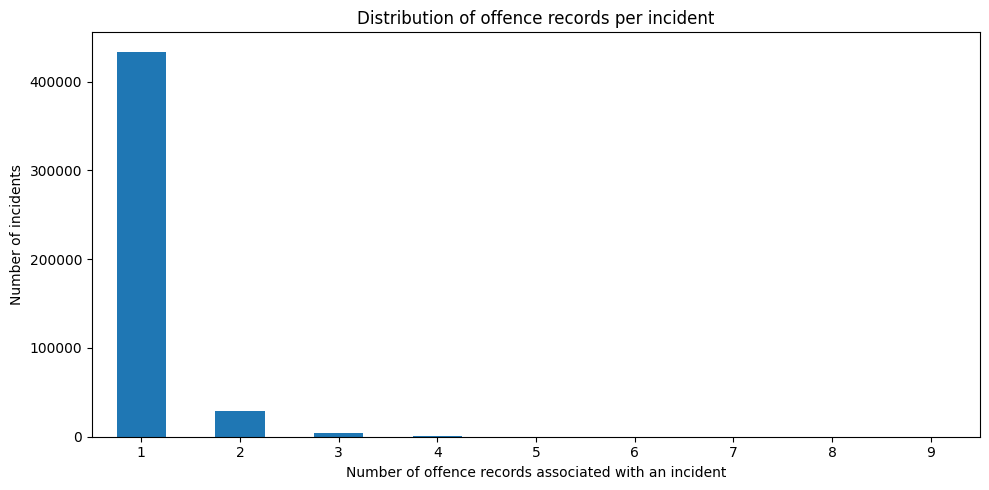

In [10]:
plt.figure(figsize=(10, 5))
incident_structure.plot(kind="bar")
plt.title("Distribution of offence records per incident")
plt.xlabel("Number of offence records associated with an incident")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


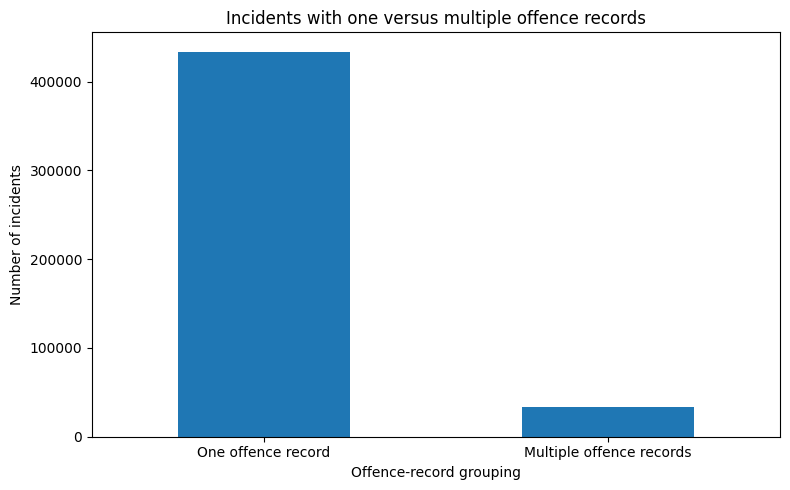

In [11]:
multiple_incident_counts = pd.Series({
    "One offence record": int((offence_counts == 1).sum()),
    "Multiple offence records": int((offence_counts > 1).sum())
})

plt.figure(figsize=(8, 5))
multiple_incident_counts.plot(kind="bar")
plt.title("Incidents with one versus multiple offence records")
plt.xlabel("Offence-record grouping")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


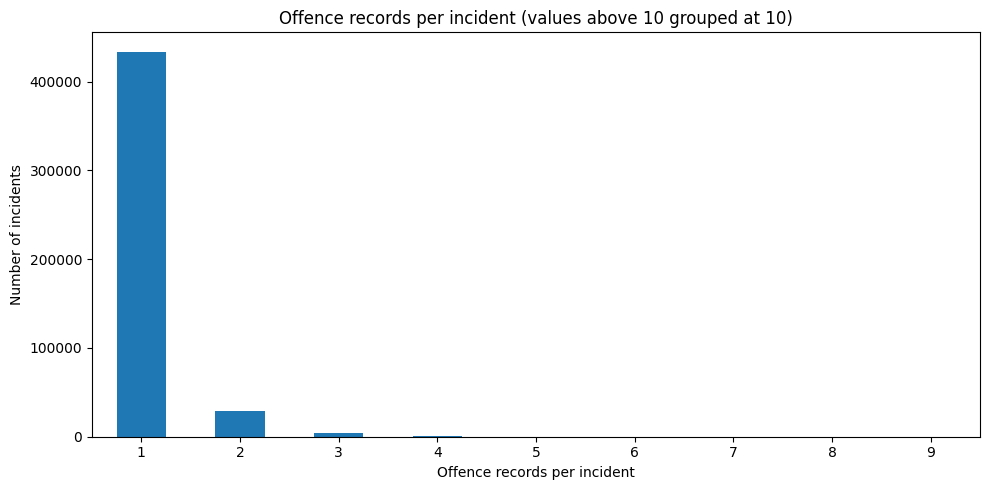

In [12]:
capped_offence_counts = offence_counts.clip(upper=10)

plt.figure(figsize=(10, 5))
capped_offence_counts.value_counts().sort_index().plot(kind="bar")
plt.title("Offence records per incident (values above 10 grouped at 10)")
plt.xlabel("Offence records per incident")
plt.ylabel("Number of incidents")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [13]:
total_incidents = incident_source["Incident ID"].nunique()
multiple_offence_incidents = int((offence_counts > 1).sum())

multiple_offence_percentage = (
    multiple_offence_incidents / total_incidents * 100
    if total_incidents else 0
)

print(f"Unique incidents: {total_incidents:,}")
print(f"Incidents with multiple offence records: {multiple_offence_incidents:,}")
print(f"Percentage with multiple offence records: {multiple_offence_percentage:.2f}%")
print(
    f"Average offence records per incident: "
    f"{len(incident_source) / total_incidents:.3f}"
    if total_incidents else "No incidents available."
)


Unique incidents: 467,601
Incidents with multiple offence records: 33,749
Percentage with multiple offence records: 7.22%
Average offence records per incident: 1.087


### Decision on aggregation

Review the statistics and visualisations above before continuing.

If incidents have multiple linked offence records, an incident-level representation is useful for questions about unique incidents. Aggregation is not a replacement for the offence-level dataset: combining records can hide offence-level detail.

The next sections construct a separate incident-level dataset while preserving unique offence codes and descriptions for incidents with multiple offence records.


## 3. Prepare the data for aggregation

Convert timestamp fields to pandas datetime values. Invalid date strings are coerced to missing values.


In [14]:
datetime_columns = [
    "Start_Date_Time",
    "End_Date_Time",
    "Dispatch Date / Time"
]

available_datetime_columns = [
    column for column in datetime_columns
    if column in incident_source.columns
]

missing_datetime_columns = [
    column for column in datetime_columns
    if column not in incident_source.columns
]

print("Available datetime columns:", available_datetime_columns)
print("Missing datetime columns:", missing_datetime_columns)


Available datetime columns: ['Start_Date_Time', 'End_Date_Time', 'Dispatch Date / Time']
Missing datetime columns: []


In [15]:
for column in available_datetime_columns:
    incident_source[column] = pd.to_datetime(
        incident_source[column],
        errors="coerce"
    )


## 4. Define aggregation helper functions

The custom `unique_values` function is only applied to incidents with multiple offence records. For incidents with a single offence record, the original value is already the unique value, so the main aggregation can use pandas' built-in `first` operation.


In [16]:
def unique_values(series):
    values = series.dropna().astype(str).unique()
    return " | ".join(values)


## 5. Identify columns for aggregation

The column checks make the notebook resilient to optional columns being absent from a revised input file.


In [17]:
offence_related_columns = [
    "Offence Code",
    "NIBRS Code",
    "Crime Name1",
    "Crime Name2",
    "Crime Name3",
    "Place",
    "Place_Clean",
    "Place_Group",
    "Agency"
]

multi_value_columns = [
    column for column in offence_related_columns
    if column in incident_source.columns
]

missing_offence_columns = [
    column for column in offence_related_columns
    if column not in incident_source.columns
]

print("Available offence-related columns:", multi_value_columns)
print("Missing offence-related columns:", missing_offence_columns)


Available offence-related columns: ['Offence Code', 'NIBRS Code', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Place', 'Place_Clean', 'Place_Group', 'Agency']
Missing offence-related columns: []


In [18]:
incident_related_columns = [
    "CR Number",
    "Police District Name",
    "Block Address",
    "City",
    "City_Clean",
    "State",
    "State_Clean",
    "Zip_Code_Clean",
    "Police District Number",
    "Sector",
    "Beat",
    "PRA",
    "Agency_Clean"
]

first_value_columns = [
    column for column in incident_related_columns
    if column in incident_source.columns
]

missing_incident_columns = [
    column for column in incident_related_columns
    if column not in incident_source.columns
]

print("Available incident-related columns:", first_value_columns)
print("Missing incident-related columns:", missing_incident_columns)


Available incident-related columns: ['CR Number', 'Police District Name', 'Block Address', 'City', 'City_Clean', 'State', 'State_Clean', 'Zip_Code_Clean', 'Police District Number', 'Sector', 'Beat', 'PRA', 'Agency_Clean']
Missing incident-related columns: []


In [19]:
quality_columns = [
    "has_valid_coords",
    "has_invalid_end_time",
    "is_not_a_crime",
    "is_90z_other",
    "is_imputed_dispatch",
    "is_midnight_start",
    "has_invalid_addr_num",
    "is_victim_outlier"
]

available_quality_columns = [
    column for column in quality_columns
    if column in incident_source.columns
]

print("Available data-quality columns:", available_quality_columns)


Available data-quality columns: ['has_valid_coords', 'has_invalid_end_time', 'is_not_a_crime', 'is_90z_other', 'is_imputed_dispatch', 'is_midnight_start', 'has_invalid_addr_num', 'is_victim_outlier']


## 6. Separate single-offence and multiple-offence incidents

This is the main performance optimisation.

- All incidents are included in the main groupby aggregation, using pandas' built-in operations.
- Only records belonging to incidents with multiple offence rows are passed through the custom unique-value aggregation.
- The multiple-offence values then replace the initial first-value result for the relevant columns.

This avoids running custom Python functions for every incident group.


In [20]:
duplicate_mask = incident_source["Incident ID"].duplicated(keep=False)

duplicate_source = incident_source.loc[duplicate_mask].copy()

print(f"Records belonging to multiple-offence incidents: {len(duplicate_source):,}")
print(f"Multiple-offence incidents: {duplicate_source['Incident ID'].nunique():,}")


Records belonging to multiple-offence incidents: 74,254
Multiple-offence incidents: 33,749


## 7. Configure the optimised aggregation

Pandas built-in aggregation functions are used wherever possible. Victim totals are calculated separately with `min_count=1` so groups with entirely missing victim values remain missing rather than becoming zero.


In [21]:
aggregation_fast = {}

for column in multi_value_columns + first_value_columns:
    aggregation_fast[column] = "first"


In [22]:
temporal_aggregation = {
    "Start_Date_Time": "min",
    "End_Date_Time": "max",
    "Dispatch Date / Time": "min"
}

for column, rule in temporal_aggregation.items():
    if column in incident_source.columns:
        aggregation_fast[column] = rule


In [23]:
coordinate_columns = [
    column for column in ["Latitude", "Longitude"]
    if column in incident_source.columns
]

for column in coordinate_columns:
    aggregation_fast[column] = "median"


In [24]:
for column in available_quality_columns:
    aggregation_fast[column] = "max"


In [25]:
if "Victims" in aggregation_fast:
    aggregation_fast.pop("Victims")


## 8. Perform the main incident-level aggregation

The main aggregation uses built-in pandas operations. Execution time is measured to help assess performance on the local machine.


In [26]:
aggregation_start = time.perf_counter()

incident_df = (
    incident_source
    .groupby("Incident ID", sort=False)
    .agg(aggregation_fast)
)

main_aggregation_seconds = time.perf_counter() - aggregation_start

print(f"Main aggregation completed in {main_aggregation_seconds:.2f} seconds")


Main aggregation completed in 1.13 seconds


## 9. Preserve multiple offence codes and descriptions

For incidents with multiple offence records, retain every unique non-missing value for each offence-related column. Single-offence incidents already have the correct value from the main aggregation.


In [27]:
multi_value_start = time.perf_counter()

if not duplicate_source.empty and multi_value_columns:
    multi_value_aggregated = (
        duplicate_source
        .groupby("Incident ID", sort=False)[multi_value_columns]
        .agg(unique_values)
    )

    incident_df.update(multi_value_aggregated)

multi_value_aggregation_seconds = time.perf_counter() - multi_value_start

print(
    "Multiple-offence aggregation completed in "
    f"{multi_value_aggregation_seconds:.2f} seconds"
)


Multiple-offence aggregation completed in 61.42 seconds


## 10. Aggregate victim–offence associations

The source `Victims` field is summed across offence records. This represents victim–offence associations and must not be interpreted as a count of distinct individuals.


In [28]:
if "Victims" in incident_source.columns:
    victim_totals = (
        incident_source
        .groupby("Incident ID", sort=False)["Victims"]
        .sum(min_count=1)
    )

    incident_df["Victims"] = victim_totals


## 11. Add the number of offence records per incident


In [29]:
offence_record_counts = (
    incident_source
    .groupby("Incident ID", sort=False)
    .size()
    .rename("Total_Offence_Records")
)

incident_df = incident_df.join(offence_record_counts)


In [30]:
incident_df = incident_df.reset_index()


## 12. Create incident-level temporal features

Temporal attributes are derived from the aggregated incident start timestamp.


In [31]:
if "Start_Date_Time" in incident_df.columns:
    incident_df["Start_Year"] = incident_df["Start_Date_Time"].dt.year


In [32]:
if "Start_Date_Time" in incident_df.columns:
    incident_df["Start_Month"] = incident_df["Start_Date_Time"].dt.month


In [33]:
if "Start_Date_Time" in incident_df.columns:
    incident_df["Start_DayOfWeek"] = incident_df["Start_Date_Time"].dt.day_name()


In [34]:
if "Start_Date_Time" in incident_df.columns:
    incident_df["Start_Hour"] = incident_df["Start_Date_Time"].dt.hour


In [35]:
if "Start_Date_Time" in incident_df.columns:
    incident_df["Is_Weekend"] = (
        incident_df["Start_Date_Time"].dt.dayofweek >= 5
    )


C:\Users\Kavindu Jayasinghe\AppData\Local\Temp\ipykernel_11584\4162499348.py:3: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  incident_df["Start_Date_Time"].dt.dayofweek >= 5


## 13. Calculate and validate incident duration

Duration is calculated as the latest available end timestamp minus the earliest start timestamp associated with the incident. It is an incident-level elapsed-time approximation, not an offence-specific duration.


In [36]:
if {"Start_Date_Time", "End_Date_Time"}.issubset(incident_df.columns):
    incident_df["Incident_Duration_Minutes"] = (
        incident_df["End_Date_Time"] - incident_df["Start_Date_Time"]
    ).dt.total_seconds() / 60


In [37]:
incident_df["Has_Missing_Start_Time"] = (
    incident_df["Start_Date_Time"].isna()
)


In [38]:
incident_df["Has_Missing_End_Time"] = (
    incident_df["End_Date_Time"].isna()
)


In [39]:
incident_df["Has_Invalid_Duration"] = (
    incident_df["Incident_Duration_Minutes"] < 0
)


In [40]:
incident_df["Duration_Status"] = np.select(
    [
        incident_df["Has_Missing_Start_Time"],
        incident_df["Has_Missing_End_Time"],
        incident_df["Has_Invalid_Duration"]
    ],
    [
        "Missing Start Time",
        "Missing End Time",
        "Invalid Negative Duration"
    ],
    default="Valid Duration"
)


In [41]:
invalid_duration_mask = (
    incident_df["Duration_Status"] != "Valid Duration"
)

incident_df.loc[
    invalid_duration_mask,
    "Incident_Duration_Minutes"
] = np.nan


## 14. Create incident-level indicators


In [42]:
incident_df["Has_Multiple_Offences"] = (
    incident_df["Total_Offence_Records"] > 1
)


In [43]:
if {"Latitude", "Longitude"}.issubset(incident_df.columns):
    incident_df["Has_Valid_Coordinates"] = (
        incident_df["Latitude"].between(-90, 90)
        & incident_df["Longitude"].between(-180, 180)
        & incident_df["Latitude"].notna()
        & incident_df["Longitude"].notna()
    )


## 15. Validate the incident-level dataset


In [44]:
print(f"Incident-level records: {len(incident_df):,}")
print(f"Number of columns: {len(incident_df.columns):,}")


Incident-level records: 467,601
Number of columns: 50


In [45]:
duplicate_incident_count = incident_df["Incident ID"].duplicated().sum()
print(f"Duplicate Incident IDs: {duplicate_incident_count:,}")


Duplicate Incident IDs: 0


In [46]:
print(f"Original offence records: {len(df):,}")
print(f"Records used for aggregation: {len(incident_source):,}")
print(f"Unique incidents created: {len(incident_df):,}")
print(
    "Records excluded due to missing Incident ID: "
    f"{len(df) - len(incident_source):,}"
)


Original offence records: 508,106
Records used for aggregation: 508,106
Unique incidents created: 467,601
Records excluded due to missing Incident ID: 0


In [47]:
offence_distribution = (
    incident_df["Total_Offence_Records"]
    .value_counts()
    .sort_index()
    .rename_axis("Offence records per incident")
    .to_frame("Number of incidents")
)

display(offence_distribution)


,Number of incidents
Offence records per incident,
1,433852
2,28603
3,3935
4,918
5,219
6,50
7,18
8,4
9,2


In [48]:
duration_summary = (
    incident_df["Duration_Status"]
    .value_counts()
    .to_frame("Number of incidents")
)

display(duration_summary)


,Number of incidents
Duration_Status,
Missing End Time,267168
Valid Duration,200433


In [49]:
if "Has_Valid_Coordinates" in incident_df.columns:
    coordinate_summary = (
        incident_df["Has_Valid_Coordinates"]
        .value_counts()
        .rename(index={
            True: "Valid coordinates",
            False: "Invalid or missing coordinates"
        })
        .to_frame("Number of incidents")
    )

    display(coordinate_summary)


,Number of incidents
Has_Valid_Coordinates,
Valid coordinates,444866
Invalid or missing coordinates,22735


In [50]:
missing_summary = pd.DataFrame({
    "Missing Values": incident_df.isna().sum(),
    "Missing Percentage": incident_df.isna().mean() * 100
})

display(
    missing_summary.sort_values(
        "Missing Percentage",
        ascending=False
    )
)


,Missing Values,Missing Percentage
Incident_Duration_Minutes,267168,57.135891
End_Date_Time,267168,57.135891
Dispatch Date / Time,68134,14.570970
Block Address,35157,7.518590
Longitude,22735,4.862051
Latitude,22735,4.862051
State,8843,1.891142
Zip_Code_Clean,90,0.019247
City_Clean,36,0.007699
City,36,0.007699


In [51]:
display(incident_df.head(10))


,Incident ID,Offence Code,NIBRS Code,Crime Name1,Crime Name2,Crime Name3,Place,Place_Clean,Place_Group,Agency,...,Start_DayOfWeek,Start_Hour,Is_Weekend,Incident_Duration_Minutes,Has_Missing_Start_Time,Has_Missing_End_Time,Has_Invalid_Duration,Duration_Status,Has_Multiple_Offences,Has_Valid_Coordinates
0,201590757,9108,90Z,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,Government Building,Government Building,"Government, Medical & Civic",MCPD,...,Monday,20,False,NaN,False,True,False,Missing End Time,False,True
1,201590749,2901,290,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - BUSINESS,Retail - Drug Store/Pharmacy,Retail - Drug Store/Pharmacy,Retail & Commercial,MCPD,...,Monday,19,False,NaN,False,True,False,Missing End Time,False,True
2,201590742,9199,90Z,Crime Against Society,All Other Offenses,POLICE INFORMATION,Residence - Other,Residence - Other,Residence & Lodging,MCPD,...,Monday,18,False,NaN,False,True,False,Missing End Time,False,True
3,201590754,9108,90Z,Crime Against Society,All Other Offenses,RECOVERED PROPERTY - MONT CO.,Residence -Townhouse/Duplex,Residence - Townhouse/Duplex,Residence & Lodging,MCPD,...,Monday,18,False,60.0,False,False,False,Valid Duration,False,True
4,201590766,9199,90Z,Crime Against Society,All Other Offenses,POLICE INFORMATION,Restaurant,Restaurant,Food & Nightlife,MCPD,...,Monday,17,False,NaN,False,True,False,Missing End Time,False,True
5,201590741,2902,290,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,Street - Commercial,Street - Commercial,Street & Roadway,MCPD,...,Monday,17,False,NaN,False,True,False,Missing End Time,False,True
6,201590733,9105,90Z,Crime Against Society,All Other Offenses,LOST PROPERTY,Street - Other,Street - Other,Street & Roadway,MCPD,...,Monday,16,False,NaN,False,True,False,Missing End Time,False,True
7,201590735,2610,26F,Crime Against Property,Identity Theft,IDENTITY THEFT,Bank - ATM,Bank - ATM,"Office, Financial & Industrial",MCPD,...,Monday,15,False,NaN,False,True,False,Missing End Time,False,True
8,201590739,9107,90Z,Crime Against Society,All Other Offenses,MISSING PERSON,School - Elementary/Secondary,School - Elementary/Secondary,School & Education,MCPD,...,Monday,15,False,NaN,False,True,False,Missing End Time,False,True
9,201590738,1399,13B,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,Street - Residential,Street - Residential,Street & Roadway,MCPD,...,Monday,15,False,NaN,False,True,False,Missing End Time,False,True


In [52]:
total_aggregation_seconds = (
    main_aggregation_seconds + multi_value_aggregation_seconds
)

print(f"Main aggregation time: {main_aggregation_seconds:.2f} seconds")
print(f"Multiple-value aggregation time: {multi_value_aggregation_seconds:.2f} seconds")
print(f"Combined aggregation time: {total_aggregation_seconds:.2f} seconds")


Main aggregation time: 1.13 seconds
Multiple-value aggregation time: 61.42 seconds
Combined aggregation time: 62.55 seconds


## 16. Export and verify the incident-level dataset

The new dataset is exported separately. The original offence-level CSV is not overwritten.


In [53]:
OUTPUT_FILE = "crime_dataset_incident_level_cleaned.csv"

incident_df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8"
)

print(f"Dataset saved successfully: {OUTPUT_FILE}")


Dataset saved successfully: crime_dataset_incident_level_cleaned.csv


In [54]:
verified_df = pd.read_csv(
    "crime_dataset_incident_level_cleaned.csv",
    low_memory=False
)

print(f"Exported records: {len(verified_df):,}")
print(f"Exported columns: {len(verified_df.columns):,}")
print(
    "Duplicate Incident IDs: "
    f"{verified_df['Incident ID'].duplicated().sum():,}"
)


Exported records: 467,601
Exported columns: 50
Duplicate Incident IDs: 0


In [55]:
verified_df.shape

(467601, 50)

## 17. Interpretation and limitations

Use the pre-aggregation statistics and visualisations to justify why an incident-level representation is useful for the group's research questions.

Important limitations:

1. `Victims` is summed across offence records. It represents victim–offence associations, not necessarily distinct people.
2. First-non-missing values for incident descriptors assume that those fields are consistent within an incident. Investigate conflicting values when precise location or classification matters.
3. Median coordinates provide a representative point when multiple offence rows have coordinates. They do not establish that the incident occurred at that exact point.
4. Incident duration uses the earliest start and latest end timestamps across associated offence records. It is not an offence-specific duration.
5. Keep the offence-level dataset for offence-level research questions. Use the incident-level dataset for questions about unique reported incidents.
6. Confirm the actual date coverage before comparing annual totals. Partial-year coverage should not be interpreted as a complete calendar year.
